# 09 Computational Efficiency and Uncertainty

**Scientific question.** Which methods trade predictive error for CPU cost?

**Learning objectives.** Calculate real-time factor and dependence-aware uncertainty.

**Prerequisites.** Install the project requirements. Configure the data directory for raw-record checks. Portable evidence review also uses the existing run artifacts.

**Dataset and run.** Course gearbox at 3.2 kHz, the project’s designated training and held-out development records, and the explicit diagnostic or blind availability files where relevant.

**Execution.** This clean-kernel replay reads the evidence cited in each code cell. Use the explicit project pipeline for full fitting and the notebook build script for review replay. The companion guide contains notation, figures, and worked examples.

In [1]:
import hashlib
import json
import os
from pathlib import Path
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
from IPython.display import Image, display

hint = os.environ.get("SRC_PROJECT_DIR")
locations = [Path(hint).resolve()] if hint else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in locations if (p / "src" / "src_gearbox").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open within the project or set SRC_PROJECT_DIR.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
DATA = Path(os.environ.get("SRC_DATA_DIR", ROOT / "data" / "raw"))
RESULTS = ROOT / "results"
START = 1792
N = 24000
pd.options.display.max_colwidth = 120
pd.options.display.width = 115
plt.rcParams.update({"figure.dpi": 105, "axes.grid": True, "grid.alpha": .18})

def table(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return None
    return pd.read_csv(file)

def evidence(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    return json.loads(file.read_text(encoding="utf-8"))

def show_fig(relative, width=780):
    file = ROOT / relative
    if file.is_file():
        display(Image(filename=str(file), width=width))
    else:
        print(f"NOT AVAILABLE YET · {relative}")

def forecast(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    with np.load(file, allow_pickle=False) as source:
        arrays = {key: source[key] for key in source.files}
    np.testing.assert_array_equal(arrays["target_indices"], np.arange(START, N))
    assert np.isfinite(arrays["actual"]).all()
    return arrays

def align_forecasts(reference, *others):
    for other in others:
        for key in ("target_indices", "actual", "rpm", "time_s"):
            np.testing.assert_array_equal(reference[key], other[key])

def draw_forecast(bundle, keys, view=slice(5000, 5200)):
    if not bundle:
        return
    y, t = bundle["actual"], bundle["time_s"]
    fig, ax = plt.subplots(2, 1, figsize=(9.0, 4.0), sharex=True, layout="constrained")
    ax[0].plot(t[view], y[view], color="#141a26", lw=1.2, label="Measured")
    for key, label in keys.items():
        if key in bundle:
            pred = bundle[key]
            ax[0].plot(t[view], pred[view], lw=0.9, label=label)
            ax[1].plot(t[view], (y-pred)[view], lw=0.9, label=label)
    ax[0].legend(ncol=3, fontsize=8)
    ax[0].set_ylabel("Std. vibration")
    ax[1].set(ylabel="Std. residual", xlabel="Acquisition time (s)")
    plt.show()

print("Read-only evidence replay.", f"Python {platform.python_version()}",
      f"NumPy {np.__version__}. One-step observed history through t−1.")

Read-only evidence replay. Python 3.12.14 NumPy 2.5.5. One-step observed history through t−1.


### Cost and uncertainty on a matched record

Batch real-time factor is median processing seconds divided by record
duration. It includes feature construction according to the measured call
scope. An amortized sample cost does not establish the deadline for the
next sample. Inspect load, cold and warm timings separately when available.
Parameter count and checkpoint bytes complement but do not replace RAM or
operation counts. CPU measurements do not imply CUDA availability.

Adjacent squared errors are correlated. Form the pairwise sequence
$d_t=e_{A,t}^2-e_{B,t}^2$ and resample blocks of that same sequence.
Distinct block lengths expose dependence sensitivity, not independent-rig
transfer. See Companion Chapter 18.

,model,mse,fit_s,warm_median_ms,warm_iqr_ms,parameters,checkpoint_bytes,RTF_7p5s
19,ar,0.440566,0.247201,0.333181,0.018056,96.0,2855.0,0.000044
21,arx,0.443197,0.141087,1.136264,0.060780,101.0,2915.0,0.000152
20,arma,0.441706,1.862997,9.869808,3.235770,98.0,2889.0,0.001316
18,arima,0.440065,1.909362,13.577459,3.783840,98.0,2880.0,0.001810
14,mlp,0.406424,0.849119,19.862254,17.283152,7050.0,29004.0,0.002648
10,sparse_lpv_ar,0.381496,3.294303,66.094638,26.646612,475.0,5510.0,0.008813
8,sparse_lpv_arma,0.371406,5.188056,87.959670,20.368592,840.0,8908.0,0.011728
16,lstm,0.408813,3.950984,173.859097,38.315088,4314.0,18880.0,0.023181
13,cnn,0.394638,5.806604,181.201037,32.238136,5826.0,24566.0,0.024160
2,archived_src_local_corrected,0.318606,NaN,184.808112,37.716483,2789.0,NaN,0.024641


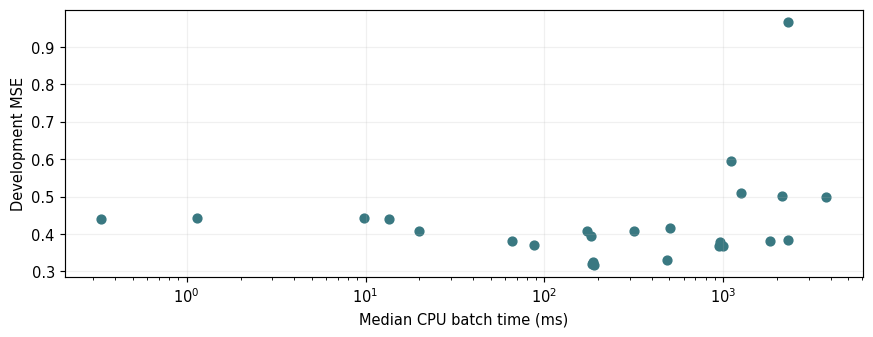

Environment fields ['platform', 'python', 'packages', 'logical_cpu_count', 'process_affinity_count', 'host_memory', 'free_bytes', 'git_status', 'gpu']
Recorded comparator timing measurements: 147


,model,seeds,mean_mse,sd_mse,min_mse,max_mse
0,mlp,3,0.411704,0.005796,0.406424,0.417906
1,lstm,3,0.413832,0.004362,0.408813,0.416711
2,cnn,3,0.397804,0.003005,0.394638,0.400616
3,transformer,3,0.501870,0.009914,0.490637,0.509394


In [2]:
metrics = table("results/metrics/all_model_comparison.csv")
if metrics is not None:
    cols = ["model","mse","fit_s","warm_median_ms","warm_iqr_ms","warm_p95_ms",
            "parameters","checkpoint_bytes"]
    selected = metrics[[k for k in cols if k in metrics]].copy()
    if "warm_median_ms" in selected:
        selected["RTF_7p5s"] = selected.warm_median_ms / 7500
        display(selected.sort_values("warm_median_ms").head(22))
        good = selected.dropna(subset=["warm_median_ms","mse"])
        fig, ax = plt.subplots(figsize=(8.2, 3.1), layout="constrained")
        ax.scatter(good.warm_median_ms,good.mse,c="#397881")
        ax.set(xscale="log",xlabel="Median CPU batch time (ms)",ylabel="Development MSE")
        plt.show()
hardware = evidence("results/environment_intake.json")
print("Environment fields",list(hardware))
timings = table("results/timings/baseline_repeats.csv")
if timings is not None:
    print(f"Recorded comparator timing measurements: {len(timings)}")
seeds = table("results/metrics/baseline_seed_sensitivity_summary.csv")
if seeds is not None:
    display(seeds)

In [3]:
from src_gearbox.comparison import blocked

group = forecast("results/predictions/src_sigvalid.npz")
benchmark = forecast("results/predictions/baselines_sigvalid.npz")
if group and benchmark:
    actual = group["actual"]
    align_forecasts(group,benchmark)
    delta = (actual-benchmark["sparse_lpv_arma"])**2 - (actual-group["primary_pi_src"])**2
    recorded = table("results/statistical_tests/paired_moving_block.csv")
    rows = []
    for block in (320,640,1280):
        lower,upper = blocked(delta,block,2000,19)
        if recorded is not None:
            ref = recorded.loc[recorded.model.eq("sparse_lpv_arma") & recorded.block_samples.eq(block)].iloc[0]
            np.testing.assert_allclose((delta.mean(),lower,upper),
                (ref.delta_mse,ref.interval_low,ref.interval_high),atol=1e-12,rtol=0)
        rows.append((block,delta.mean(),lower,upper))
    display(pd.DataFrame(rows,columns=["samples","paired delta","low 95%","high 95%"]))

,samples,paired delta,low 95%,high 95%
0,320,0.041432,0.036634,0.046438
1,640,0.041432,0.036319,0.047242
2,1280,0.041432,0.035531,0.047057


### Interpretation and limits

The plotted difference is relative to a strict comparator on the same
record. Bootstrapping blocks preserves pairing and local dependence within
each draw. Confidence limits cannot account for differences between machines,
sensor mountings or new acquisitions absent from the study.

Read the [Companion Guide](../docs/companion_guide.md) and the [Project README](../README.md).